In [ ]:
# how to import all the tools

from src.tools.registry import TOOLS, auto_import_tools, export_tools_doc
auto_import_tools()
print(TOOLS)
print("已注册工具：", list(TOOLS.keys()))
print(export_tools_doc("markdown"))


### 1 Check .nc Data

In [1]:
import netCDF4 as nc
import numpy as np

def view_nc_info(file_path):
    """
    查看NetCDF文件的详细信息
    
    参数:
        file_path: NC文件路径
    """
    try:
        # 打开NC文件
        dataset = nc.Dataset(file_path, 'r')
        
        print("=" * 80)
        print(f"NetCDF文件信息: {file_path}")
        print("=" * 80)
        
        # 1. 全局属性
        print("\n【全局属性】")
        print("-" * 80)
        if dataset.ncattrs():
            for attr in dataset.ncattrs():
                print(f"{attr}: {dataset.getncattr(attr)}")
        else:
            print("无全局属性")
        
        # 2. 维度信息
        print("\n【维度信息】")
        print("-" * 80)
        print(f"{'维度名称':<20} {'大小':<15} {'是否无限'}")
        print("-" * 80)
        for dim_name, dim in dataset.dimensions.items():
            unlimited = "是" if dim.isunlimited() else "否"
            print(f"{dim_name:<20} {len(dim):<15} {unlimited}")
        
        # 3. 变量信息
        print("\n【变量信息】")
        print("=" * 80)
        for var_name, var in dataset.variables.items():
            print(f"\n变量名: {var_name}")
            print(f"  数据类型: {var.dtype}")
            print(f"  维度: {var.dimensions}")
            print(f"  形状: {var.shape}")
            
            # 变量属性
            if var.ncattrs():
                print(f"  属性:")
                for attr in var.ncattrs():
                    print(f"    {attr}: {var.getncattr(attr)}")
            
            # 数据示例（显示前几个值）
            print(f"  数据示例:")
            try:
                data = var[:]
                if data.size > 0:
                    if data.ndim == 1:
                        # 一维数组
                        preview = data[:min(5, len(data))]
                        print(f"    前{len(preview)}个值: {preview}")
                        if len(data) > 5:
                            print(f"    ... (共{len(data)}个值)")
                    elif data.ndim == 2:
                        # 二维数组
                        print(f"    左上角 (前3x3):")
                        preview = data[:min(3, data.shape[0]), :min(3, data.shape[1])]
                        print(f"    {preview}")
                    else:
                        # 多维数组
                        print(f"    数据形状: {data.shape}")
                        print(f"    最小值: {np.nanmin(data)}")
                        print(f"    最大值: {np.nanmax(data)}")
                        print(f"    平均值: {np.nanmean(data):.4f}")
                else:
                    print("    (空数组)")
            except Exception as e:
                print(f"    无法读取数据: {e}")
        
        # 4. 数据组信息（如果有）
        if dataset.groups:
            print("\n【数据组】")
            print("-" * 80)
            for group_name in dataset.groups:
                print(f"组名: {group_name}")
        
        print("\n" + "=" * 80)
        print("信息查看完成")
        print("=" * 80)
        
        # 关闭文件
        dataset.close()
        
    except FileNotFoundError:
        print(f"错误: 找不到文件 '{file_path}'")
    except Exception as e:
        print(f"错误: {e}")

# 使用示例
if __name__ == "__main__":
    # 请替换为你的NC文件路径
    nc_file = "/data1/lorraine-20419/jingwei_QA/woa23_climatology/nitrate_all_time_periods/woa23_all_n00_01.nc"
    view_nc_info(nc_file)
    
    # 或者交互式输入文件路径
    # file_path = input("请输入NC文件路径: ")
    # view_nc_info(file_path)

NetCDF文件信息: /data1/lorraine-20419/jingwei_QA/woa23_climatology/nitrate_all_time_periods/woa23_all_n00_01.nc

【全局属性】
--------------------------------------------------------------------------------
Conventions: CF-1.6
title: World Ocean Atlas 2023 : moles_of_nitrate_per_unit_mass_in_sea_water Annual 1965-2022 1.00 degree
summary: 
references: Paver, C.R., H.E. Garcia, C. Bouchard, S.L. Cross, Z. Wang, J.R. Reagan, T.P. Boyer, R.A. Locarnini, A.V. Mishonov, O.K. Baranova, D. Seidov, and D. Dukhovskoy (2023). Nitrate [in "World Ocean Atlas 2023 Volume 4: Dissolved Inorganic Nutrients (phosphate, nitrate, silicate)"]. A. Mishonov Technical Ed., NOAA Atlas NESDIS 92, https://doi.org/10.25923/39qw-7j08.
institution: NOAA National Centers for Environmental Information (NCEI)
comment: Global Climatology as part of the World Ocean Atlas Project
id: woa23_all_n00_01.nc
naming_authority: gov.noaa.ncei
time_coverage_start: 1965-01-01
time_coverage_duration: P58Y
time_coverage_resolution: P01Y
geos

### 2 Test Functions

In [1]:
import sys 
sys.path.append("/home/lorraine/jingwei_QA")

#### 2.1 Data Loader

In [ ]:
from src.tools.data_loader import load_regular_data

path = "/data1/lorraine-20419/jingwei_QA/reconstruction/recon_no3_sjtu_jingwei_v1_1.zarr"
da = load_regular_data(path, time_range=("2000-01-01", "2010-12-31"), depth_range=(0, 100), lat_range=(20, 30), lon_range=(120, 130))
print(da)


<xarray.DataArray 'n' (time: 132, depth: 21, lat: 10, lon: 10)> Size: 2MB
[277200 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 1kB 2000-01-01 2000-02-01 ... 2010-12-01
  * depth    (depth) float32 84B 0.0 5.0 10.0 15.0 20.0 ... 85.0 90.0 95.0 100.0
  * lat      (lat) float32 40B 20.5 21.5 22.5 23.5 24.5 25.5 26.5 27.5 28.5 29.5
  * lon      (lon) float32 40B 120.5 121.5 122.5 123.5 ... 127.5 128.5 129.5
Attributes:
    long_name:  nitrate
    units:      μmol·kg^-1


In [6]:
from src.tools.data_loader import load_areas
areas = load_areas(lat_range=(20, 30), lon_range=(120, 130))
print(areas)


<xarray.DataArray (lat: 10, lon: 10)> Size: 800B
array([[1.15485634e+10, 1.15485634e+10, 1.15485634e+10, 1.15485634e+10,
        1.15485634e+10, 1.15485634e+10, 1.15485634e+10, 1.15485634e+10,
        1.15485634e+10, 1.15485634e+10],
       [1.14732328e+10, 1.14732328e+10, 1.14732328e+10, 1.14732328e+10,
        1.14732328e+10, 1.14732328e+10, 1.14732328e+10, 1.14732328e+10,
        1.14732328e+10, 1.14732328e+10],
       [1.13944509e+10, 1.13944509e+10, 1.13944509e+10, 1.13944509e+10,
        1.13944509e+10, 1.13944509e+10, 1.13944509e+10, 1.13944509e+10,
        1.13944509e+10, 1.13944509e+10],
       [1.13122369e+10, 1.13122369e+10, 1.13122369e+10, 1.13122369e+10,
        1.13122369e+10, 1.13122369e+10, 1.13122369e+10, 1.13122369e+10,
        1.13122369e+10, 1.13122369e+10],
       [1.12266109e+10, 1.12266109e+10, 1.12266109e+10, 1.12266109e+10,
        1.12266109e+10, 1.12266109e+10, 1.12266109e+10, 1.12266109e+10,
        1.12266109e+10, 1.12266109e+10],
       [1.11375942e+10, 1.

In [4]:
from src.tools.data_loader import load_depth_levels
depths, depth_bnds = load_depth_levels()
print(depths)
print(depth_bnds)

<xarray.DataArray (depth: 102)> Size: 408B
array([0.00e+00, 5.00e+00, 1.00e+01, 1.50e+01, 2.00e+01, 2.50e+01,
       3.00e+01, 3.50e+01, 4.00e+01, 4.50e+01, 5.00e+01, 5.50e+01,
       6.00e+01, 6.50e+01, 7.00e+01, 7.50e+01, 8.00e+01, 8.50e+01,
       9.00e+01, 9.50e+01, 1.00e+02, 1.25e+02, 1.50e+02, 1.75e+02,
       2.00e+02, 2.25e+02, 2.50e+02, 2.75e+02, 3.00e+02, 3.25e+02,
       3.50e+02, 3.75e+02, 4.00e+02, 4.25e+02, 4.50e+02, 4.75e+02,
       5.00e+02, 5.50e+02, 6.00e+02, 6.50e+02, 7.00e+02, 7.50e+02,
       8.00e+02, 8.50e+02, 9.00e+02, 9.50e+02, 1.00e+03, 1.05e+03,
       1.10e+03, 1.15e+03, 1.20e+03, 1.25e+03, 1.30e+03, 1.35e+03,
       1.40e+03, 1.45e+03, 1.50e+03, 1.55e+03, 1.60e+03, 1.65e+03,
       1.70e+03, 1.75e+03, 1.80e+03, 1.85e+03, 1.90e+03, 1.95e+03,
       2.00e+03, 2.10e+03, 2.20e+03, 2.30e+03, 2.40e+03, 2.50e+03,
       2.60e+03, 2.70e+03, 2.80e+03, 2.90e+03, 3.00e+03, 3.10e+03,
       3.20e+03, 3.30e+03, 3.40e+03, 3.50e+03, 3.60e+03, 3.70e+03,
       3.80e+03, 3.

#### 2.2 Basic Calculator

In [2]:
from src.tools.data_loader import load_regular_data
from src.tools.basic_calculator import compute_basic_stat

path = "/data1/lorraine-20419/jingwei_QA/reconstruction/recon_o2_sjtu_jingwei_v1_1.zarr"
da = load_regular_data(path, time_range=("2000-01-01", "2010-12-31"), depth_range=(0, 100), lat_range=(20, 30), lon_range=(120, 130))
da_2 = compute_basic_stat(da, op="mean", dim=["depth", "lat", "lon"])
print(da_2)

<xarray.DataArray 'o2' (time: 132)> Size: 1kB
array([210.89885027, 214.31993963, 212.97848951, 210.37628806,
       207.56129416, 204.85940778, 203.20793193, 201.46855735,
       200.9944119 , 200.79584885, 202.50025299, 204.23537641,
       210.11835358, 213.50268457, 214.06790481, 209.84058853,
       206.79256915, 203.66830954, 201.0824953 , 199.22662297,
       199.61895551, 200.86663503, 203.15305102, 206.25103948,
       212.3808254 , 214.81127228, 214.16647089, 209.88090023,
       209.07802007, 206.26672888, 201.80753112, 200.63236516,
       199.74966882, 199.85892876, 203.69367603, 206.88815065,
       210.6384999 , 213.52027243, 213.91936921, 210.40505909,
       207.96117225, 205.02213961, 200.66401299, 198.45352981,
       198.68285221, 200.28315282, 202.134053  , 205.42636504,
       210.57701972, 213.53454991, 214.45368858, 209.44683226,
       207.36262717, 204.03413672, 201.47530632, 199.93041799,
       199.84050557, 201.61786192, 203.55359789, 205.59756861,
       21

In [3]:
from src.tools.basic_calculator import fit_1D_trend

fit_res = fit_1D_trend(da_2)
print(fit_res)

{'fitted_data': <xarray.DataArray (time: 132)> Size: 1kB
array([210.2060342 , 212.34466361, 212.74893073, 211.31032574,
       208.41498635, 204.84005417, 201.5450811 , 199.41447491,
       199.02011421, 200.46784985, 203.36909331, 206.9451183 ,
       210.23607958, 212.35864618, 212.74309743, 211.28624228,
       208.37911701, 204.80202667, 201.51510246, 199.40059173,
       199.0260529 , 200.49201638, 203.40500113, 206.98312935,
       210.26599125, 212.37242986, 212.73705341, 211.26199285,
       208.34317099, 204.76403237, 201.48525798, 199.38690766,
       199.03220219, 200.5163485 , 203.44098506, 207.0211066 ,
       210.2957683 , 212.38601422, 212.73079888, 211.23757822,
       208.30714941, 204.72607245, 201.45554859, 199.37342313,
       199.03856192, 200.54084547, 203.47704401, 207.0590489 ,
       210.32540981, 212.39939883, 212.72433401, 211.21299911,
       208.27105338, 204.68814807, 201.42597518, 199.36013854,
       199.04513188, 200.56550652, 203.51317686, 207.09695507

#### 2.3 Scientific Calculator

In [2]:
from src.tools.scientific_calculator import compute_anomaly
from src.tools.data_loader import load_regular_data

path = "/data1/lorraine-20419/jingwei_QA/reconstruction/recon_no3_sjtu_jingwei_v1_1.zarr"
da = load_regular_data(path, time_range=("2000-01-01", "2010-12-31"), depth_range=(0, 100))

anom = compute_anomaly(da, 'no3', freq="month", method="subtract")
# print(anom)

from src.tools.basic_calculator import compute_basic_stat
anom_mean = compute_basic_stat(anom, op="mean", dim=["time", "depth"])
print(anom_mean)


<xarray.DataArray (lat: 173, lon: 360)> Size: 498kB
array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       ...,
       [2.55077304, 2.55559672, 2.56051235, ..., 2.52480603, 2.53318783,
        2.54201274],
       [2.61092703, 2.62192825, 2.63285724, ..., 2.58626782, 2.59003299,
        2.59761592],
       [2.6729577 , 2.67718377, 2.67975068, ..., 2.66837579, 2.66541895,
        2.66694396]], shape=(173, 360))
Coordinates:
  * lat      (lat) float32 692B -82.5 -81.5 -80.5 -79.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float32 1kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5


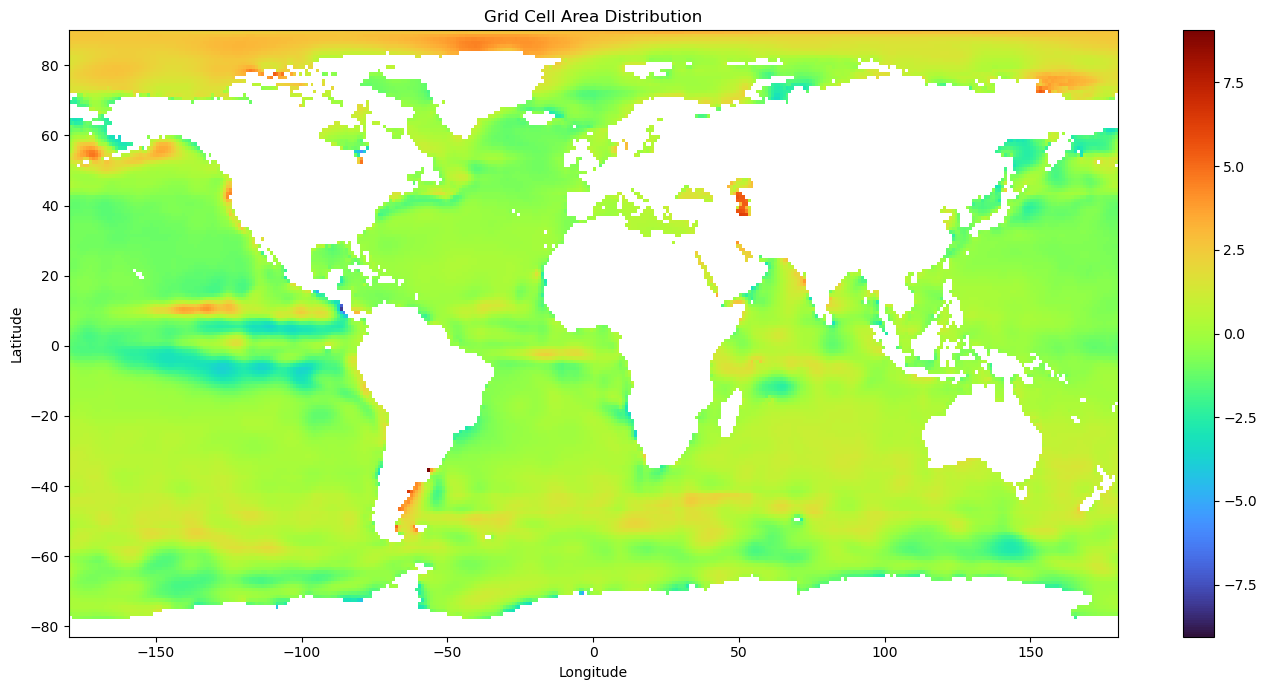

In [3]:
import matplotlib.pyplot as plt

da_mean = compute_basic_stat(da, op="mean", dim=["time", "depth"])

import xarray as xr
clim = xr.open_dataset('/data1/lorraine-20419/jingwei_QA/woa23_climatology/nitrate_all_time_periods/woa23_all_n01_01.nc', decode_times=False)['n_an']
clim_mean = compute_basic_stat(clim, op="mean", dim=["time", "depth"])

anom_mean.plot(figsize=(14, 7), cmap='turbo')
plt.title('Grid Cell Area Distribution')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()